# Train Benchmark Final
So sánh phương pháp lượng tử và cổ điển. Binary trên ba benchmark đã xử lý. Các phần V2, V4 và ablation giữ nguyên cấu hình đã chạy; checkpoint trên Drive được tái sử dụng. Không chọn lại cấu hình theo test. Đây là tổng hợp thực nghiệm khám phá, không phải benchmark độc lập mới.

## A. Baseline cổ điển và lượng tử (V2 Lite)

## Cell 0 — Mount Drive, cài thư viện

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%pip -q install qiskit xgboost
from pathlib import Path
BASE = Path('/content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae')
assert (BASE/'data/std').exists(), 'Kiểm tra lại BASE'
OUT = BASE/'output/train_v2_lite'
OUT.mkdir(parents=True, exist_ok=True)
print(BASE, OUT)

Mounted at /content/drive
/content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae /content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae/output/train_v2_lite


## Cell 1 — Imports, cấu hình và loader Zenodo (tự nhận header)

In [2]:
import numpy as np, pandas as pd, hashlib, time, json, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score, balanced_accuracy_score, roc_auc_score, confusion_matrix)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
torch.set_num_threads(2)
FEATURES = [f'f{i}' for i in range(1,7)]
DATASETS = ['cicddos2019','cicids2017','nsl-kdd']
K = 2       # smoke/full pilot; đổi 5 cho đánh giá cuối
SEEDS = [42] # đánh giá cuối: [42,1,2]
FIT_N = 50
VAL_N = 50
LAYERS = 1
MAX_IT = 60
EPOCHS = 60
PREPROCESS = 'minmax' # hoặc log1p (chỉ feature không âm trong train)
MODELS = ['MLP','RF','XGBoost','CNN','QNN','QAE+MLP','QAE+QNN']

def read_zenodo(ds):
    hits = list((BASE/'data/std/data/standard_datasets/processed').rglob(f'{ds}_processed.csv'))
    if not hits:
        hits = list((BASE/'data/std').rglob(f'{ds}_processed.csv'))
        if len(hits)>1 and len({hashlib.sha256(p.read_bytes()).hexdigest() for p in hits})==1:
            hits = [sorted(hits)[0]]
    assert len(hits)==1, (ds,hits)
    d = pd.read_csv(hits[0], header=None)
    assert d.shape[1]==7, d.shape
    first = d.iloc[0].astype(str).str.strip().str.lower().tolist()
    if first == FEATURES+['label']: d=d.iloc[1:]
    d.columns=FEATURES+['label']
    for c in d: d[c]=pd.to_numeric(d[c],errors='raise')
    assert set(d.label.unique()) <= {0,1}, 'Nhãn không phải binary'
    return d.reset_index(drop=True)
raw = {ds:read_zenodo(ds) for ds in DATASETS}
for ds,d in raw.items(): print(ds,d.shape,d.label.value_counts().to_dict()); display(d.head(3))

cicddos2019 (1000, 7) {1: 500, 0: 500}


,f1,f2,f3,f4,f5,f6,label
0,2,0.0,49.0,4.081633e+04,0.0,0,1
1,2,0.0,2.0,1.000000e+06,0.0,0,1
2,2,0.0,1.0,2.000000e+06,0.0,0,1


cicids2017 (1000, 7) {1: 500, 0: 500}


,f1,f2,f3,f4,f5,f6,label
0,2,0.0,997.000,2006.018054,0.000000,0,1
1,8,0.0,10377.000,110.133675,1.632740,0,1
2,12,0.0,7747365.455,0.140810,1.963198,0,1


nsl-kdd (1000, 7) {1: 500, 0: 500}


,f1,f2,f3,f4,f5,f6,label
0,0,1.545455,255,0.0,1.0,0,1
1,0,4.578947,255,0.0,0.0,0,1
2,0,3.714286,255,0.0,1.0,0,1


## Cell 2 — Audit, làm sạch; giữ nhóm feature trùng cùng fold
Loại dòng trùng hoàn toàn (cả nhãn), giữ mẫu xung đột nhãn để không che giấu hạn chế. Không xóa cột f6 vì cần giữ kích thước mạch; scaler đưa cột hằng về 0. Nhóm theo vector đầu vào, không bảo đảm chống leakage theo thời gian/PCAP vì benchmark thiếu metadata.

In [3]:
def audit_clean(raw, folder):
    folder.mkdir(parents=True,exist_ok=True)
    rows=[]; cleaned={}
    for ds,d in raw.items():
        X=d[FEATURES]
        c=d.replace([np.inf,-np.inf],np.nan).dropna().drop_duplicates().reset_index(drop=True)
        groups=c.groupby(FEATURES,dropna=False).label.nunique()
        rows.append(dict(dataset=ds,original=len(d),clean=len(c),nan=int(d.isna().sum().sum()),inf=int(np.isinf(X.to_numpy()).sum()),duplicates=int(d.duplicated().sum()),conflicts=int((groups>1).sum()),constant=','.join(k for k in FEATURES if c[k].nunique()<=1),counts=str(c.label.value_counts().to_dict())))
        cleaned[ds]=c
    a=pd.DataFrame(rows); a.to_csv(folder/'audit.csv',index=False); display(a)
    return cleaned
cleaned=audit_clean(raw,OUT/'binary')

,dataset,original,clean,nan,inf,duplicates,conflicts,constant,counts
0,cicddos2019,1000,588,0,0,412,3,f6,"{0: 461, 1: 127}"
1,cicids2017,1000,886,0,0,114,3,f6,"{0: 470, 1: 416}"
2,nsl-kdd,1000,955,0,0,45,1,,"{0: 499, 1: 456}"


## Cell 3 — Split và chuẩn hóa không leakage
Outer test chỉ dùng đánh giá. QAE fit và calibration chỉ dùng normal, tách khỏi tập huấn luyện classifier; mọi classifier dùng cùng tập còn lại. Class weight áp dụng trên train cho RF/XGB/CNN/QNN; MLP và QAE+MLP dùng oversampling trên train khi lệch lớp. Không cân bằng test. Với raw có session/time, nên bổ sung group theo capture nếu metadata còn tồn tại.

In [4]:
def split_data(d,k,seed):
    X=d[FEATURES].to_numpy(float); enc=LabelEncoder().fit(d.label); y=enc.transform(d.label)
    assert str(enc.classes_[0]).lower() in ('0','benign','normal'), enc.classes_
    g=pd.util.hash_pandas_object(d[FEATURES],index=False).to_numpy()
    for tr,te in StratifiedGroupKFold(k,shuffle=True,random_state=seed).split(X,y,g):
        assert not set(g[tr])&set(g[te])
        assert len(np.unique(y[te]))==len(enc.classes_), 'Fold thiếu lớp: giảm K hoặc thêm dữ liệu'
        # giữ các nhóm normal riêng biệt; loại toàn bộ nhóm fit/val khỏi classifier
        rng=np.random.default_rng(seed); normals=tr[y[tr]==0]; ng=rng.permutation(np.unique(g[normals]))
        a=[]; v=[]; used=set()
        for group in ng:
            ix=normals[g[normals]==group]
            if len(a)<FIT_N: a.extend(ix); used.add(group)
            elif len(v)<VAL_N: v.extend(ix); used.add(group)
            else: break
        fit=np.array(a[:FIT_N],int); val=np.array(v[:VAL_N],int)
        cl=tr[~np.isin(g[tr],list(used))]
        assert len(fit)==FIT_N and len(val)==VAL_N and len(np.unique(y[cl]))==len(enc.classes_), 'Thiếu normal/group hoặc lớp: giảm FIT_N, VAL_N hay K'
        yield X,y,enc,fit,val,cl,te

def make_scaler(Xfit):
    logmask=(Xfit>=0).all(0) & (np.max(Xfit,axis=0)>0) if PREPROCESS=='log1p' else np.zeros(Xfit.shape[1],bool)
    def transform(A):
        A=A.copy(); A[:,logmask]=np.log1p(np.maximum(A[:,logmask],0)); return A
    sc=MinMaxScaler(clip=True).fit(transform(Xfit))
    return sc,logmask

def scale(A,sc,mask):
    A=A.copy(); A[:,mask]=np.log1p(np.maximum(A[:,mask],0)); return sc.transform(A)

for ds,d in cleaned.items():
    X,y,enc,fit,val,cl,te=next(split_data(d,K,42)); print(ds,len(fit),len(val),len(cl),len(te),enc.classes_)

cicddos2019 50 50 193 295 [0 1]
cicids2017 50 50 342 443 [0 1]
nsl-kdd 50 50 378 477 [0 1]


## Cell 4 — QAE V2: mạch 3 qubit, tối ưu fidelity trực tiếp
Mạch mới: mỗi layer 3 góc/qubit và CX vòng. Dùng amplitude encoding (vector 0 được ánh xạ |0⟩), tối ưu L-BFGS-B trên ma trận mật độ trung bình của tập fit. Trash q2; F=P(q2=0). SWAP test lý tưởng cho P(aux=0)=(1+F)/2. Đây là objective đúng cho trash fidelity, không phải sai số tái tạo vector cổ điển.

In [5]:
def amplitudes(A):
    Z=np.pad(A,((0,0),(0,2))).astype(float); norms=np.linalg.norm(Z,axis=1)
    Z[norms==0,0]=1; return Z/np.linalg.norm(Z,axis=1,keepdims=True)
def encoder(theta,layers):
    qc=QuantumCircuit(3); t=np.asarray(theta).reshape(layers,3,3)
    for layer in t:
        for i,(a,b,c) in enumerate(layer): qc.rx(a,i); qc.ry(b,i); qc.rz(c,i)
        qc.cx(0,1); qc.cx(1,2); qc.cx(2,0)
    return qc

def qae_fit(A,seed,layers=LAYERS):
    Z=amplitudes(A); rho=Z.T@Z/len(Z)
    def loss(t):
        U=Operator(encoder(t,layers)).data; R=U@rho@U.conj().T
        return float(1-np.trace(R[:4,:4]).real)
    t0=np.random.default_rng(seed).normal(0,.2,9*layers)
    r=minimize(loss,t0,method='L-BFGS-B',options={'maxiter':MAX_IT,'ftol':1e-9})
    return r.x,dict(loss=float(r.fun),iterations=int(r.nit),converged=bool(r.success),message=str(r.message))

def qae_features(A,t,layers=LAYERS):
    Z=amplitudes(A)@Operator(encoder(t,layers)).data.T
    p=np.abs(Z)**2
    score=p[:,4:].sum(1)
    latent=p[:,:4]+p[:,4:] # marginal probabilities of q0,q1
    return np.column_stack([score,latent])

# smoke test: kiểm chứng SWAP test bằng statevector 5 qubit
X,y,enc,fit,val,cl,te=next(split_data(cleaned['cicddos2019'],K,42))
sc,mask=make_scaler(X[fit]); A=scale(X[fit],sc,mask)
t,info=qae_fit(A,42); print(info)
qc=QuantumCircuit(5); qc.initialize(amplitudes(A[:1])[0],[0,1,2]); qc.compose(encoder(t,LAYERS),[0,1,2],inplace=True); qc.h(4); qc.cswap(4,2,3); qc.h(4)
p0=Statevector.from_instruction(qc).probabilities([4])[0]
s=qae_features(A[:1],t)[0,0]
assert np.isclose(s,2*(1-p0),atol=1e-8)
print('SWAP check OK:',s); display(qc.draw(output='text'))

{'loss': 0.2703765051751734, 'iterations': 18, 'converged': True, 'message': 'CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL'}
SWAP check OK: 0.004374004311678723


┌─────────────────────────────────────────────────────────────┐»
q_0: ┤0                                                            ├»
     │                                                             │»
q_1: ┤1 Initialize(0.0047845,0,0.0039692,0.00038683,0.99998,0,0,0) ├»
     │                                                             │»
q_2: ┤2                                                            ├»
     └─────────────────────────────────────────────────────────────┘»
q_3: ───────────────────────────────────────────────────────────────»
                                  ┌───┐                             »
q_4: ─────────────────────────────┤ H ├─────────────────────────────»
                                  └───┘                             »
«     ┌─────────────────┐┌─────────────┐  ┌─────────────┐            ┌───┐   »
«q_0: ┤ Rx(-1.1955e-06) ├┤ Ry(-3.1568) ├──┤ Rz(0.15009) ├────■───────┤ X ├───»
«     └──┬────────────┬─┘├─────────────┤  ├─────────────┴┐ ┌─┴─┐     └─┬─┘   »
«q_1: ───┤ Rx(3.1416) ├──┤ Ry(-3.2631) ├──┤ Rz(-0.26044) ├─┤ X ├──■────┼─────»
«     ┌──┴────────────┴─┐├─────────────┴┐┌┴──────────────┴┐└───┘┌─┴─┐  │     »
«q_2: ┤ Rx(-1.4048e-06) ├┤ Ry(0.058905) ├┤ Rz(-0.0033645) ├─────┤ X ├──■───X─»
«     └─────────────────┘└──────────────┘└────────────────┘     └───┘      │ »
«q_3: ─────────────────────────────────────────────────────────────────────X─»
«                                                                          │ »
«q_4: ─────────────────────────────────────────────────────────────────────■─»
«                                                                            »
«          
«q_0: ─────
«          
«q_1: ─────
«          
«q_2: ─────
«          
«q_3: ─────
«     ┌───┐
«q_4: ┤ H ├
«     └───┘

## Cell 5 — QNN biến phân và CNN
QNN dùng 3 qubit với 6 phép Ry mã hóa, CX và 2 lớp Ry/CX có tham số học được; đầu phân loại cổ điển nhận 8 xác suất đo, hỗ trợ multiclass. Hybrid QAE+QNN ghép 5 đặc trưng QAE vào đầu phân loại. Mô phỏng statevector thực (cổng Ry/CX), không phải phần cứng thật.

In [6]:
def ry(state,angle,q):
    # state[:, i], bit q theo thứ tự little endian của Qiskit
    idx=torch.arange(8,device=state.device); partner=idx^(1<<q)
    sign=torch.where((idx&(1<<q))==0,-1.,1.)
    a=angle.reshape(-1,1)/2
    return torch.cos(a)*state+torch.sin(a)*state[:,partner]*sign

def cx(state,c,t):
    idx=torch.arange(8,device=state.device); return state[:,idx^(((idx>>c)&1)<<t)]

def ring(s):
    for c,t in [(0,1),(1,2),(2,0)]: s=cx(s,c,t)
    return s

class VQNN(nn.Module):
    def __init__(self,nclass,extra=0):
        super().__init__(); self.theta=nn.Parameter(torch.randn(2,3)*.2); self.head=nn.Linear(8+extra,nclass)
    def forward(self,x):
        s=torch.zeros((len(x),8),device=x.device); s[:,0]=1
        for block in range(2):
            for q in range(3): s=ry(s,x[:,block*3+q]*np.pi,q)
            s=ring(s)
        for layer in self.theta:
            for q in range(3): s=ry(s,layer[q],q)
            s=ring(s)
        return self.head(torch.cat([s.square(),x[:,6:]],dim=1))

class CNN(nn.Module):
    def __init__(self,nclass):
        super().__init__(); self.net=nn.Sequential(nn.Conv1d(1,16,3,padding=1),nn.ReLU(),nn.Conv1d(16,16,3,padding=1),nn.ReLU(),nn.Flatten(),nn.Linear(96,nclass))
    def forward(self,x): return self.net(x.unsqueeze(1))

def train_torch(model,A,y,B,seed):
    opt=torch.optim.Adam(model.parameters(),lr=.01,weight_decay=1e-4)
    weights=torch.tensor(len(y)/(len(np.unique(y))*np.bincount(y)),dtype=torch.float32)
    loss=nn.CrossEntropyLoss(weight=weights)
    dl=DataLoader(TensorDataset(torch.tensor(A,dtype=torch.float32),torch.tensor(y,dtype=torch.long)),batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(seed))
    model.train()
    for epoch in range(EPOCHS):
        for x,t in dl:
            opt.zero_grad(); l=loss(model(x),t); l.backward(); opt.step()
    model.eval()
    with torch.no_grad(): p=model(torch.tensor(B,dtype=torch.float32)).softmax(1).numpy()
    return model,p

# kiểm tra cổng Ry/CX với Qiskit
s=torch.zeros(1,8); s[:,0]=1; s=ry(s,torch.tensor(.7),1); s=cx(s,1,2)
qc=QuantumCircuit(3); qc.ry(.7,1); qc.cx(1,2)
assert np.allclose(s.numpy()[0],Statevector.from_instruction(qc).data,atol=1e-6)
print('QNN gate check OK')

QNN gate check OK


## Cell 6 — Các mô hình và metrics

In [7]:
def oversample(A,y,seed):
    rng=np.random.default_rng(seed); n=np.bincount(y).max(); ids=np.concatenate([rng.choice(np.where(y==c)[0],n,replace=(sum(y==c)<n)) for c in np.unique(y)]); rng.shuffle(ids); return A[ids],y[ids]
def classify(name,A,y,B,seed):
    nc=len(np.unique(y)); torch.manual_seed(seed)
    if name in ['CNN','QNN','QAE+QNN']:
        return train_torch(CNN(nc) if name=='CNN' else VQNN(nc,A.shape[1]-6),A,y,B,seed)
    if name in ['MLP','QAE+MLP']:
        aa,yy=oversample(A,y,seed); m=MLPClassifier(hidden_layer_sizes=(32,16),max_iter=500,alpha=.001,random_state=seed).fit(aa,yy)
    elif name=='RF': m=RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=seed,n_jobs=2).fit(A,y)
    elif name=='XGBoost': m=XGBClassifier(n_estimators=200,max_depth=4,learning_rate=.05,random_state=seed,n_jobs=2).fit(A,y,sample_weight=compute_sample_weight('balanced',y))
    else: raise ValueError(name)
    return m,m.predict_proba(B)

def metrics(y,p):
    pred=p.argmax(1); nc=p.shape[1]
    return dict(accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),macro_f1=f1_score(y,pred,average='macro',zero_division=0),weighted_f1=f1_score(y,pred,average='weighted',zero_division=0),macro_precision=precision_score(y,pred,average='macro',zero_division=0),macro_recall=recall_score(y,pred,average='macro',zero_division=0),auc=roc_auc_score(y,p[:,1]) if nc==2 else roc_auc_score(y,p,multi_class='ovr',average='macro'))

def anomaly_metrics(y,s,thr):
    y=(y!=0).astype(int); p=(s>thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    return dict(auc=roc_auc_score(y,s),accuracy=accuracy_score(y,p),recall=tp/(tp+fn),fpr=fp/(fp+tn),f1=f1_score(y,p,zero_division=0),threshold=float(thr))

## Cell 7 — Train theo từng fold, lưu checkpoint
QAE/Classical AE dùng cùng fit/validation/test. QAE+MLP, QAE+QNN và đối chứng dùng cùng classifier train. Không dùng anomaly score để chặn cứng mẫu normal (tránh bỏ sót do QAE). Lưu model, scaler, class mapping, indices và xác suất. Mỗi cấu hình/dữ liệu có fingerprint riêng; khi sửa code hãy đổi VERSION.

In [8]:
VERSION='v2_lite_1'
def run_all(data,mode,only=None):
    cfg=dict(version=VERSION,k=K,seeds=SEEDS,fit=FIT_N,val=VAL_N,layers=LAYERS,it=MAX_IT,epochs=EPOCHS,preprocess=PREPROCESS,models=MODELS)
    folder=OUT/mode/hashlib.sha256(json.dumps(cfg,sort_keys=True).encode()).hexdigest()[:12]; folder.mkdir(parents=True,exist_ok=True)
    (folder/'config.json').write_text(json.dumps(cfg,indent=2))
    for ds,d in data.items():
        if only and ds not in only: continue
        dh=hashlib.sha256(pd.util.hash_pandas_object(d,index=True).values.tobytes()).hexdigest()[:12]
        for seed in SEEDS:
            for fi,(X,y,enc,fit,val,cl,te) in enumerate(split_data(d,K,seed),1):
                dest=folder/f'{ds}_{dh}_s{seed}_f{fi}'; dest.mkdir(exist_ok=True)
                if (dest/'metrics.csv').exists(): print('Skip',dest.name); continue
                start=time.perf_counter(); rows=[]
                qs,qmask=make_scaler(X[fit]); cs,cmask=make_scaler(X[cl]); Q=scale(X,qs,qmask); C=scale(X,cs,cmask)
                t,info=qae_fit(Q[fit],seed); F=qae_features(Q,t); qtime=time.perf_counter()-start
                score=F[:,0]; threshold=np.quantile(score[val],.9)
                rows.append(dict(model='QAE',task='anomaly',seconds=qtime,**anomaly_metrics(y[te],score[te],threshold)))
                st_ae=time.perf_counter()
                ae=MLPRegressor(hidden_layer_sizes=(4,2,4),max_iter=1000,random_state=seed).fit(Q[fit],Q[fit])
                s=np.linalg.norm(Q-ae.predict(Q),axis=1)
                rows.append(dict(model='ClassicalAE',task='anomaly',seconds=time.perf_counter()-st_ae,**anomaly_metrics(y[te],s[te],np.quantile(s[val],.9))))
                joblib.dump(ae,dest/'ClassicalAE.joblib')
                joblib.dump(dict(qae_theta=t,qae_info=info,qae_layers=LAYERS,qae_scaler=qs,qae_logmask=qmask,classifier_scaler=cs,classifier_logmask=cmask,classes=enc.classes_,threshold=threshold,fit=fit,val=val,cl=cl,te=te),dest/'pipeline.joblib')
                np.savez_compressed(dest/'anomaly.npz',y=y[te],score=score[te],val_score=score[val])
                for name in MODELS:
                    st=time.perf_counter(); A,B=C[cl],C[te]
                    if name.startswith('QAE+'):
                        A=np.column_stack([A,F[cl]]); B=np.column_stack([B,F[te]])
                    m,p=classify(name,A,y[cl],B,seed)
                    rows.append(dict(model=name,task='classification',seconds=time.perf_counter()-st,**metrics(y[te],p)))
                    if isinstance(m,nn.Module): torch.save(m.state_dict(),dest/f'{name}.pt')
                    else: joblib.dump(m,dest/f'{name}.joblib')
                    np.savez_compressed(dest/f'{name}_pred.npz',y=y[te],prob=p,classes=enc.classes_.astype(str))
                    print(ds,seed,fi,name,round(rows[-1]['macro_f1'],4),flush=True)
                result=pd.DataFrame(rows).assign(dataset=ds,seed=seed,fold=fi,data_hash=dh)
                tmp=dest/'metrics.tmp'; result.to_csv(tmp,index=False); tmp.replace(dest/'metrics.csv')
    return folder

## Cell 8 — Pilot CIC-DDoS2019 (2 fold, 1 seed)
Chạy trước, xem có lỗi hay không. Nếu đổi thông số, thư mục kết quả mới được tạo.

In [9]:
BINARY_RUN=run_all(cleaned,'binary',only=['cicddos2019'])
print(BINARY_RUN)

Skip cicddos2019_9f218da7e1ac_s42_f1
Skip cicddos2019_9f218da7e1ac_s42_f2
/content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae/output/train_v2_lite/binary/b413000dc828


## Cell 9 — Tổng hợp pilot và chạy cả 3 dataset
Cell này tự chạy cả 3 benchmark binary, dùng checkpoint của pilot. Cấu hình mặc định K=2, SEEDS=[42] là baseline ban đầu, không phải đánh giá cuối 5-fold.


In [10]:
def summarize(folder):
    files=list(folder.glob('*/metrics.csv')); assert files,'Chưa có fold hoàn thành'
    r=pd.concat([pd.read_csv(p) for p in files],ignore_index=True)
    # không trộn phiên bản dataset khác nhau
    assert r.groupby('dataset').data_hash.nunique().max()==1,'Có nhiều phiên bản data; dùng thư mục mới'
    r.to_csv(folder/'all_metrics.csv',index=False)
    for task,cols in [('classification',['accuracy','macro_f1','macro_recall','auc','seconds']),('anomaly',['accuracy','recall','fpr','auc','f1'])]:
        z=r[r.task==task]; s=z.groupby(['dataset','model'])[cols].agg(['mean','std','count']); display(s.round(4)); s.to_csv(folder/f'{task}_summary.csv')
    return r
r=summarize(BINARY_RUN)
# Chạy toàn bộ benchmark sau khi pilot ổn:
BINARY_RUN=run_all(cleaned,'binary')
r=summarize(BINARY_RUN)

accuracy               macro_f1                \
                        mean     std count     mean     std count   
dataset     model                                                   
cicddos2019 CNN       0.8810  0.0090     2   0.8321  0.0086     2   
            MLP       0.8659  0.0980     2   0.8373  0.1112     2   
            QAE+MLP   0.8964  0.0404     2   0.8651  0.0526     2   
            QAE+QNN   0.8366  0.0441     2   0.7826  0.0620     2   
            QNN       0.8945  0.0294     2   0.8301  0.0323     2   
            RF        0.9574  0.0170     2   0.9379  0.0216     2   
            XGBoost   0.9728  0.0047     2   0.9604  0.0093     2   
cicids2017  CNN       0.8104  0.0383     2   0.8084  0.0393     2   
            MLP       0.8093  0.0431     2   0.8062  0.0448     2   
            QAE+MLP   0.8070  0.0144     2   0.8066  0.0146     2   
            QAE+QNN   0.7167  0.0048     2   0.7158  0.0049     2   
            QNN       0.7032  0.0495     2   0.6978  0.0495     2   
            RF        0.8679  0.0080     2   0.8679  0.0080     2   
            XGBoost   0.8679  0.0112     2   0.8678  0.0113     2   
nsl-kdd     CNN       0.8565  0.0165     2   0.8541  0.0147     2   
            MLP       0.8502  0.0254     2   0.8476  0.0236     2   
            QAE+MLP   0.8712  0.0313     2   0.8697  0.0317     2   
            QAE+QNN   0.8586  0.0224     2   0.8573  0.0218     2   
            QNN       0.8230  0.0101     2   0.8158  0.0156     2   
            RF        0.9173  0.0046     2   0.9172  0.0045     2   
            XGBoost   0.9141  0.0061     2   0.9140  0.0060     2   

                    macro_recall                   auc               seconds  \
                            mean     std count    mean     std count    mean   
dataset     model                                                              
cicddos2019 CNN           0.8600  0.0871     2  0.9795  0.0121     2  4.3810   
            MLP           0.9128  0.0564     2  0.9783  0.0103     2  0.5704   
            QAE+MLP       0.9202  0.0220     2  0.9788  0.0008     2  0.3612   
            QAE+QNN       0.8243  0.1047     2  0.9447  0.0411     2  0.8927   
            QNN           0.8021  0.0251     2  0.9314  0.0015     2  0.8295   
            RF            0.9401  0.0308     2  0.9923  0.0004     2  0.4284   
            XGBoost       0.9712  0.0042     2  0.9900  0.0052     2  0.2260   
cicids2017  CNN           0.8079  0.0394     2  0.8521  0.0347     2  0.7008   
            MLP           0.8053  0.0439     2  0.8588  0.0269     2  0.4988   
            QAE+MLP       0.8077  0.0165     2  0.8360  0.0011     2  0.4809   
            QAE+QNN       0.7161  0.0041     2  0.8130  0.0113     2  2.0713   
            QNN           0.6977  0.0477     2  0.7009  0.0203     2  1.3048   
            RF            0.8714  0.0101     2  0.9541  0.0088     2  0.3580   
            XGBoost       0.8702  0.0147     2  0.9405  0.0029     2  0.0558   
nsl-kdd     CNN           0.8522  0.0128     2  0.9078  0.0141     2  0.7500   
            MLP           0.8457  0.0216     2  0.9100  0.0160     2  0.6849   
            QAE+MLP       0.8684  0.0306     2  0.9027  0.0122     2  0.4189   
            QAE+QNN       0.8559  0.0207     2  0.8996  0.0157     2  2.2096   
            QNN           0.8156  0.0162     2  0.8851  0.0254     2  1.3154   
            RF            0.9182  0.0051     2  0.9814  0.0003     2  0.3531   
            XGBoost       0.9143  0.0066     2  0.9777  0.0004     2  0.0425   

                                   
                        std count  
dataset     model                  
cicddos2019 CNN      5.5815     2  
            MLP      0.3207     2  
            QAE+MLP  0.0026     2  
            QAE+QNN  0.0356     2  
            QNN      0.0031     2  
            RF       0.0915     2  
            XGBoost  0.2676     2  
cicids2017  CNN      0.0001     2  
            MLP      0.0249     2  
          

accuracy                recall                   fpr  \
                            mean     std count    mean     std count    mean   
dataset     model                                                              
cicddos2019 ClassicalAE   0.8298  0.0682     2  0.4900  0.1939     2  0.0741   
            QAE           0.7212  0.0275     2  0.3364  0.0442     2  0.1729   
cicids2017  ClassicalAE   0.6050  0.0543     2  0.2518  0.1292     2  0.0805   
            QAE           0.4910  0.0303     2  0.0167  0.0097     2  0.0899   
nsl-kdd     ClassicalAE   0.7173  0.0123     2  0.5479  0.0298     2  0.1288   
            QAE           0.5036  0.0363     2  0.0356  0.0381     2  0.0683   

                                          auc                    f1          \
                            std count    mean     std count    mean     std   
dataset     model                                                             
cicddos2019 ClassicalAE  0.0209     2  0.8534  0.0276     2  0.5506  0.1726   
            QAE          0.0371     2  0.5548  0.2608     2  0.3436  0.0753   
cicids2017  ClassicalAE  0.0282     2  0.7329  0.0363     2  0.3657  0.1473   
            QAE          0.0443     2  0.4329  0.0399     2  0.0295  0.0160   
nsl-kdd     ClassicalAE  0.0430     2  0.8354  0.0136     2  0.6491  0.0085   
            QAE          0.0131     2  0.2925  0.0066     2  0.0632  0.0671   

                               
                        count  
dataset     model              
cicddos2019 ClassicalAE     2  
            QAE             2  
cicids2017  ClassicalAE     2  
            QAE             2  
nsl-kdd     ClassicalAE     2  
            QAE             2

Skip cicddos2019_9f218da7e1ac_s42_f1
Skip cicddos2019_9f218da7e1ac_s42_f2
Skip cicids2017_f9ca68a4db7d_s42_f1
Skip cicids2017_f9ca68a4db7d_s42_f2
Skip nsl-kdd_5395fa362f21_s42_f1
Skip nsl-kdd_5395fa362f21_s42_f2


accuracy               macro_f1                \
                        mean     std count     mean     std count   
dataset     model                                                   
cicddos2019 CNN       0.8810  0.0090     2   0.8321  0.0086     2   
            MLP       0.8659  0.0980     2   0.8373  0.1112     2   
            QAE+MLP   0.8964  0.0404     2   0.8651  0.0526     2   
            QAE+QNN   0.8366  0.0441     2   0.7826  0.0620     2   
            QNN       0.8945  0.0294     2   0.8301  0.0323     2   
            RF        0.9574  0.0170     2   0.9379  0.0216     2   
            XGBoost   0.9728  0.0047     2   0.9604  0.0093     2   
cicids2017  CNN       0.8104  0.0383     2   0.8084  0.0393     2   
            MLP       0.8093  0.0431     2   0.8062  0.0448     2   
            QAE+MLP   0.8070  0.0144     2   0.8066  0.0146     2   
            QAE+QNN   0.7167  0.0048     2   0.7158  0.0049     2   
            QNN       0.7032  0.0495     2   0.6978  0.0495     2   
            RF        0.8679  0.0080     2   0.8679  0.0080     2   
            XGBoost   0.8679  0.0112     2   0.8678  0.0113     2   
nsl-kdd     CNN       0.8565  0.0165     2   0.8541  0.0147     2   
            MLP       0.8502  0.0254     2   0.8476  0.0236     2   
            QAE+MLP   0.8712  0.0313     2   0.8697  0.0317     2   
            QAE+QNN   0.8586  0.0224     2   0.8573  0.0218     2   
            QNN       0.8230  0.0101     2   0.8158  0.0156     2   
            RF        0.9173  0.0046     2   0.9172  0.0045     2   
            XGBoost   0.9141  0.0061     2   0.9140  0.0060     2   

                    macro_recall                   auc               seconds  \
                            mean     std count    mean     std count    mean   
dataset     model                                                              
cicddos2019 CNN           0.8600  0.0871     2  0.9795  0.0121     2  4.3810   
            MLP           0.9128  0.0564     2  0.9783  0.0103     2  0.5704   
            QAE+MLP       0.9202  0.0220     2  0.9788  0.0008     2  0.3612   
            QAE+QNN       0.8243  0.1047     2  0.9447  0.0411     2  0.8927   
            QNN           0.8021  0.0251     2  0.9314  0.0015     2  0.8295   
            RF            0.9401  0.0308     2  0.9923  0.0004     2  0.4284   
            XGBoost       0.9712  0.0042     2  0.9900  0.0052     2  0.2260   
cicids2017  CNN           0.8079  0.0394     2  0.8521  0.0347     2  0.7008   
            MLP           0.8053  0.0439     2  0.8588  0.0269     2  0.4988   
            QAE+MLP       0.8077  0.0165     2  0.8360  0.0011     2  0.4809   
            QAE+QNN       0.7161  0.0041     2  0.8130  0.0113     2  2.0713   
            QNN           0.6977  0.0477     2  0.7009  0.0203     2  1.3048   
            RF            0.8714  0.0101     2  0.9541  0.0088     2  0.3580   
            XGBoost       0.8702  0.0147     2  0.9405  0.0029     2  0.0558   
nsl-kdd     CNN           0.8522  0.0128     2  0.9078  0.0141     2  0.7500   
            MLP           0.8457  0.0216     2  0.9100  0.0160     2  0.6849   
            QAE+MLP       0.8684  0.0306     2  0.9027  0.0122     2  0.4189   
            QAE+QNN       0.8559  0.0207     2  0.8996  0.0157     2  2.2096   
            QNN           0.8156  0.0162     2  0.8851  0.0254     2  1.3154   
            RF            0.9182  0.0051     2  0.9814  0.0003     2  0.3531   
            XGBoost       0.9143  0.0066     2  0.9777  0.0004     2  0.0425   

                                   
                        std count  
dataset     model                  
cicddos2019 CNN      5.5815     2  
            MLP      0.3207     2  
            QAE+MLP  0.0026     2  
            QAE+QNN  0.0356     2  
            QNN      0.0031     2  
            RF       0.0915     2  
            XGBoost  0.2676     2  
cicids2017  CNN      0.0001     2  
            MLP      0.0249     2  
          

accuracy                recall                   fpr  \
                            mean     std count    mean     std count    mean   
dataset     model                                                              
cicddos2019 ClassicalAE   0.8298  0.0682     2  0.4900  0.1939     2  0.0741   
            QAE           0.7212  0.0275     2  0.3364  0.0442     2  0.1729   
cicids2017  ClassicalAE   0.6050  0.0543     2  0.2518  0.1292     2  0.0805   
            QAE           0.4910  0.0303     2  0.0167  0.0097     2  0.0899   
nsl-kdd     ClassicalAE   0.7173  0.0123     2  0.5479  0.0298     2  0.1288   
            QAE           0.5036  0.0363     2  0.0356  0.0381     2  0.0683   

                                          auc                    f1          \
                            std count    mean     std count    mean     std   
dataset     model                                                             
cicddos2019 ClassicalAE  0.0209     2  0.8534  0.0276     2  0.5506  0.1726   
            QAE          0.0371     2  0.5548  0.2608     2  0.3436  0.0753   
cicids2017  ClassicalAE  0.0282     2  0.7329  0.0363     2  0.3657  0.1473   
            QAE          0.0443     2  0.4329  0.0399     2  0.0295  0.0160   
nsl-kdd     ClassicalAE  0.0430     2  0.8354  0.0136     2  0.6491  0.0085   
            QAE          0.0131     2  0.2925  0.0066     2  0.0632  0.0671   

                               
                        count  
dataset     model              
cicddos2019 ClassicalAE     2  
            QAE             2  
cicids2017  ClassicalAE     2  
            QAE             2  
nsl-kdd     ClassicalAE     2  
            QAE             2

## Cell 10 — Confusion matrix và biểu đồ báo cáo
Chọn một fold để xem confusion matrix, không chọn fold đẹp nhất.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
z=r[r.task=='classification']; tab=z.groupby(['dataset','model']).macro_f1.mean().unstack(); ax=tab.plot.bar(figsize=(12,5),ylim=(0,1)); ax.set_ylabel('Macro F1'); plt.tight_layout(); plt.savefig(BINARY_RUN/'macro_f1.png',dpi=180); plt.show()
p=sorted(BINARY_RUN.glob('cicddos2019*/QAE+QNN_pred.npz'))[0]; z=np.load(p); ConfusionMatrixDisplay.from_predictions(z['y'],z['prob'].argmax(1),display_labels=z['classes']); plt.tight_layout(); plt.savefig(BINARY_RUN/'hybrid_confusion.png',dpi=180); plt.show()

## B. Mô hình lượng tử cải tiến (V4)
Khởi tạo lại các hàm và biến của phần này; không dùng chung namespace huấn luyện với A.

## Cell 0 — Mount Drive

In [11]:
from google.colab import drive
drive.mount('/content/drive')
%pip -q install qiskit xgboost
from pathlib import Path
BASE = Path('/content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae')
assert (BASE/'data/std').exists(), 'Kiểm tra lại BASE'
OUT = BASE/'output/train_v4'
OUT.mkdir(parents=True, exist_ok=True)
print(BASE, OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae /content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae/output/train_v4


## Cell 1 — Loader, audit và split giống V2

In [12]:
import numpy as np, pandas as pd, hashlib, time, json, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score, balanced_accuracy_score, roc_auc_score, confusion_matrix)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
torch.set_num_threads(2)
FEATURES = [f'f{i}' for i in range(1,7)]
DATASETS = ['cicddos2019','cicids2017','nsl-kdd']
K = 2       # smoke/full pilot; đổi 5 cho đánh giá cuối
SEEDS = [42] # đánh giá cuối: [42,1,2]
FIT_N = 50
VAL_N = 50
LAYERS = 1
MAX_IT = 60
EPOCHS = 60
PREPROCESS = 'minmax' # hoặc log1p (chỉ feature không âm trong train)
MODELS = ['MLP','RF','XGBoost','CNN','QNN','QAE+MLP','QAE+QNN']

def read_zenodo(ds):
    hits = list((BASE/'data/std/data/standard_datasets/processed').rglob(f'{ds}_processed.csv'))
    if not hits:
        hits = list((BASE/'data/std').rglob(f'{ds}_processed.csv'))
        if len(hits)>1 and len({hashlib.sha256(p.read_bytes()).hexdigest() for p in hits})==1:
            hits = [sorted(hits)[0]]
    assert len(hits)==1, (ds,hits)
    d = pd.read_csv(hits[0], header=None)
    assert d.shape[1]==7, d.shape
    first = d.iloc[0].astype(str).str.strip().str.lower().tolist()
    if first == FEATURES+['label']: d=d.iloc[1:]
    d.columns=FEATURES+['label']
    for c in d: d[c]=pd.to_numeric(d[c],errors='raise')
    assert set(d.label.unique()) <= {0,1}, 'Nhãn không phải binary'
    return d.reset_index(drop=True)
raw = {ds:read_zenodo(ds) for ds in DATASETS}
for ds,d in raw.items(): print(ds,d.shape,d.label.value_counts().to_dict()); display(d.head(3))
def audit_clean(raw, folder):
    folder.mkdir(parents=True,exist_ok=True)
    rows=[]; cleaned={}
    for ds,d in raw.items():
        X=d[FEATURES]
        c=d.replace([np.inf,-np.inf],np.nan).dropna().drop_duplicates().reset_index(drop=True)
        groups=c.groupby(FEATURES,dropna=False).label.nunique()
        rows.append(dict(dataset=ds,original=len(d),clean=len(c),nan=int(d.isna().sum().sum()),inf=int(np.isinf(X.to_numpy()).sum()),duplicates=int(d.duplicated().sum()),conflicts=int((groups>1).sum()),constant=','.join(k for k in FEATURES if c[k].nunique()<=1),counts=str(c.label.value_counts().to_dict())))
        cleaned[ds]=c
    a=pd.DataFrame(rows); a.to_csv(folder/'audit.csv',index=False); display(a)
    return cleaned
cleaned=audit_clean(raw,OUT/'binary')
def split_data(d,k,seed):
    X=d[FEATURES].to_numpy(float); enc=LabelEncoder().fit(d.label); y=enc.transform(d.label)
    assert str(enc.classes_[0]).lower() in ('0','benign','normal'), enc.classes_
    g=pd.util.hash_pandas_object(d[FEATURES],index=False).to_numpy()
    for tr,te in StratifiedGroupKFold(k,shuffle=True,random_state=seed).split(X,y,g):
        assert not set(g[tr])&set(g[te])
        assert len(np.unique(y[te]))==len(enc.classes_), 'Fold thiếu lớp: giảm K hoặc thêm dữ liệu'
        # giữ các nhóm normal riêng biệt; loại toàn bộ nhóm fit/val khỏi classifier
        rng=np.random.default_rng(seed); normals=tr[y[tr]==0]; ng=rng.permutation(np.unique(g[normals]))
        a=[]; v=[]; used=set()
        for group in ng:
            ix=normals[g[normals]==group]
            if len(a)<FIT_N: a.extend(ix); used.add(group)
            elif len(v)<VAL_N: v.extend(ix); used.add(group)
            else: break
        fit=np.array(a[:FIT_N],int); val=np.array(v[:VAL_N],int)
        cl=tr[~np.isin(g[tr],list(used))]
        assert len(fit)==FIT_N and len(val)==VAL_N and len(np.unique(y[cl]))==len(enc.classes_), 'Thiếu normal/group hoặc lớp: giảm FIT_N, VAL_N hay K'
        yield X,y,enc,fit,val,cl,te

def make_scaler(Xfit):
    logmask=(Xfit>=0).all(0) & (np.max(Xfit,axis=0)>0) if PREPROCESS=='log1p' else np.zeros(Xfit.shape[1],bool)
    def transform(A):
        A=A.copy(); A[:,logmask]=np.log1p(np.maximum(A[:,logmask],0)); return A
    sc=MinMaxScaler(clip=True).fit(transform(Xfit))
    return sc,logmask

def scale(A,sc,mask):
    A=A.copy(); A[:,mask]=np.log1p(np.maximum(A[:,mask],0)); return sc.transform(A)

for ds,d in cleaned.items():
    X,y,enc,fit,val,cl,te=next(split_data(d,K,42)); print(ds,len(fit),len(val),len(cl),len(te),enc.classes_)

cicddos2019 (1000, 7) {1: 500, 0: 500}


,f1,f2,f3,f4,f5,f6,label
0,2,0.0,49.0,4.081633e+04,0.0,0,1
1,2,0.0,2.0,1.000000e+06,0.0,0,1
2,2,0.0,1.0,2.000000e+06,0.0,0,1


cicids2017 (1000, 7) {1: 500, 0: 500}


,f1,f2,f3,f4,f5,f6,label
0,2,0.0,997.000,2006.018054,0.000000,0,1
1,8,0.0,10377.000,110.133675,1.632740,0,1
2,12,0.0,7747365.455,0.140810,1.963198,0,1


nsl-kdd (1000, 7) {1: 500, 0: 500}


,f1,f2,f3,f4,f5,f6,label
0,0,1.545455,255,0.0,1.0,0,1
1,0,4.578947,255,0.0,0.0,0,1
2,0,3.714286,255,0.0,1.0,0,1


,dataset,original,clean,nan,inf,duplicates,conflicts,constant,counts
0,cicddos2019,1000,588,0,0,412,3,f6,"{0: 461, 1: 127}"
1,cicids2017,1000,886,0,0,114,3,f6,"{0: 470, 1: 416}"
2,nsl-kdd,1000,955,0,0,45,1,,"{0: 499, 1: 456}"


cicddos2019 50 50 193 295 [0 1]
cicids2017 50 50 342 443 [0 1]
nsl-kdd 50 50 378 477 [0 1]


## Cell 2 — QAE: amplitude encoding có/không có biên độ neo; kiểm tra SWAP

In [13]:
def amplitudes(A):
    Z=np.pad(A,((0,0),(0,2))).astype(float); norms=np.linalg.norm(Z,axis=1)
    Z[norms==0,0]=1; return Z/np.linalg.norm(Z,axis=1,keepdims=True)
def encoder(theta,layers):
    qc=QuantumCircuit(3); t=np.asarray(theta).reshape(layers,3,3)
    for layer in t:
        for i,(a,b,c) in enumerate(layer): qc.rx(a,i); qc.ry(b,i); qc.rz(c,i)
        qc.cx(0,1); qc.cx(1,2); qc.cx(2,0)
    return qc

def qae_fit(A,seed,layers=LAYERS):
    Z=amplitudes(A); rho=Z.T@Z/len(Z)
    def loss(t):
        U=Operator(encoder(t,layers)).data; R=U@rho@U.conj().T
        return float(1-np.trace(R[:4,:4]).real)
    t0=np.random.default_rng(seed).normal(0,.2,9*layers)
    r=minimize(loss,t0,method='L-BFGS-B',options={'maxiter':MAX_IT,'ftol':1e-9})
    return r.x,dict(loss=float(r.fun),iterations=int(r.nit),converged=bool(r.success),message=str(r.message))

def qae_features(A,t,layers=LAYERS):
    Z=amplitudes(A)@Operator(encoder(t,layers)).data.T
    p=np.abs(Z)**2
    score=p[:,4:].sum(1)
    latent=p[:,:4]+p[:,4:] # marginal probabilities of q0,q1
    return np.column_stack([score,latent])


def encode_v4(A, anchor):
    if anchor == 0: return amplitudes(A)
    Z=np.column_stack([A, np.full(len(A),anchor), np.zeros(len(A))])
    return Z/np.linalg.norm(Z,axis=1,keepdims=True)

def fit_v4(A,seed,depth,anchor):
    Z=encode_v4(A,anchor); rho=Z.T@Z/len(Z)
    def loss(t):
        U=Operator(encoder(t,depth)).data
        return float(1-np.trace((U@rho@U.conj().T)[:4,:4]).real)
    r=minimize(loss,np.random.default_rng(seed).normal(0,.2,9*depth),method='L-BFGS-B',options={'maxiter':100,'ftol':1e-9})
    return r.x, float(r.fun), bool(r.success)

def features_v4(A,t,depth,anchor):
    p=np.abs(encode_v4(A,anchor)@Operator(encoder(t,depth)).data.T)**2
    return np.column_stack([p[:,4:].sum(1),p[:,:4]+p[:,4:]])

A=np.random.default_rng(42).random((10,6)); t,_,_=fit_v4(A,42,2,1.)
qc=QuantumCircuit(5); qc.initialize(encode_v4(A[:1],1.)[0],[0,1,2]); qc.compose(encoder(t,2),[0,1,2],inplace=True); qc.h(4); qc.cswap(4,2,3); qc.h(4)
assert np.isclose(features_v4(A[:1],t,2,1.)[0,0],2*(1-Statevector.from_instruction(qc).probabilities([4])[0]),atol=1e-8)
print('SWAP check OK')


SWAP check OK


## Cell 3 — QNN cải tiến: depth, learning rate, early stopping, feature fusion

In [14]:
def ry(state,angle,q):
    # state[:, i], bit q theo thứ tự little endian của Qiskit
    idx=torch.arange(8,device=state.device); partner=idx^(1<<q)
    sign=torch.where((idx&(1<<q))==0,-1.,1.)
    a=angle.reshape(-1,1)/2
    return torch.cos(a)*state+torch.sin(a)*state[:,partner]*sign

def cx(state,c,t):
    idx=torch.arange(8,device=state.device); return state[:,idx^(((idx>>c)&1)<<t)]

def ring(s):
    for c,t in [(0,1),(1,2),(2,0)]: s=cx(s,c,t)
    return s

class VQNN(nn.Module):
    def __init__(self,nclass,extra=0):
        super().__init__(); self.theta=nn.Parameter(torch.randn(2,3)*.2); self.head=nn.Linear(8+extra,nclass)
    def forward(self,x):
        s=torch.zeros((len(x),8),device=x.device); s[:,0]=1
        for block in range(2):
            for q in range(3): s=ry(s,x[:,block*3+q]*np.pi,q)
            s=ring(s)
        for layer in self.theta:
            for q in range(3): s=ry(s,layer[q],q)
            s=ring(s)
        return self.head(torch.cat([s.square(),x[:,6:]],dim=1))


from sklearn.preprocessing import StandardScaler
import copy
class ImprovedQNN(nn.Module):
    def __init__(self, extra, depth, fusion_weight=1.):
        super().__init__(); self.theta=nn.Parameter(torch.randn(depth,3)*.2)
        self.head=nn.Linear(8+extra,2); self.fusion_weight=fusion_weight
    def forward(self,x):
        s=torch.zeros((len(x),8),device=x.device); s[:,0]=1
        for block in range(2):
            for q in range(3): s=ry(s,x[:,block*3+q]*np.pi,q)
            s=ring(s)
        for layer in self.theta:
            for q in range(3): s=ry(s,layer[q],q)
            s=ring(s)
        return self.head(torch.cat([s.square(),x[:,6:]*self.fusion_weight],dim=1))

def predict_v4(m,A):
    m.eval()
    with torch.no_grad(): return m(torch.tensor(A,dtype=torch.float32)).softmax(1).numpy()

def tune_one(A,y,B,yb,seed,depth,lr,w):
    torch.manual_seed(seed); m=ImprovedQNN(A.shape[1]-6,depth,w)
    opt=torch.optim.Adam(m.parameters(),lr=lr,weight_decay=1e-4)
    loss=nn.CrossEntropyLoss(weight=torch.tensor(len(y)/(2*np.bincount(y)),dtype=torch.float32))
    dl=DataLoader(TensorDataset(torch.tensor(A,dtype=torch.float32),torch.tensor(y,dtype=torch.long)),batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(seed))
    best=-1.; best_loss=float('inf'); stale=0
    for ep in range(100):
        m.train()
        for x,t in dl:
            opt.zero_grad(); l=loss(m(x),t); l.backward(); opt.step()
        prob=predict_v4(m,B); f=f1_score(yb,prob.argmax(1),average='macro',zero_division=0)
        vl=-np.log(np.clip(prob[np.arange(len(yb)),yb],1e-9,1)).mean()
        if f>best+1e-9 or (abs(f-best)<=1e-9 and vl<best_loss-1e-6):
            best,best_loss=f,vl; state=copy.deepcopy(m.state_dict()); best_epoch=ep+1; stale=0
        else: stale+=1
        if stale>=15: break
    m.load_state_dict(state)
    return m,best,best_epoch
def metrics(y,p):
    pred=p.argmax(1); nc=p.shape[1]
    return dict(accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),macro_f1=f1_score(y,pred,average='macro',zero_division=0),weighted_f1=f1_score(y,pred,average='weighted',zero_division=0),macro_precision=precision_score(y,pred,average='macro',zero_division=0),macro_recall=recall_score(y,pred,average='macro',zero_division=0),auc=roc_auc_score(y,p[:,1]) if nc==2 else roc_auc_score(y,p,multi_class='ovr',average='macro'))

def anomaly_metrics(y,s,thr):
    y=(y!=0).astype(int); p=(s>thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    return dict(auc=roc_auc_score(y,s),accuracy=accuracy_score(y,p),recall=tp/(tp+fn),fpr=fp/(fp+tn),f1=f1_score(y,p,zero_division=0),threshold=float(thr))

## Cell 4 — Quy trình V4 theo fold
QAE fit trên cùng 50 normal như V2; 50 normal calibration chọn ngưỡng 90%. Inner validation từ classifier pool, nhóm vector giống nhau không giao nhau. QNN/Hybrid dùng cùng inner train, không refit để giữ checkpoint early stopping; do đó ít mẫu classifier train hơn V2, ghi rõ khi so sánh. QAE lựa chọn theo AUC inner validation; không đảo dấu score. Hybrid thử cả QAE baseline và QAE đã chọn, với/không chuẩn hóa feature fusion. Thời gian bao gồm tìm cấu hình, không so trực tiếp với thời gian train đơn V2.

In [15]:
BASELINE=BASE/'output/train_v2_lite/binary/b413000dc828'
assert (BASELINE/'all_metrics.csv').exists(), 'Kiểm tra đường dẫn kết quả V2 đã chạy'
RUN=OUT/'binary'/'v4_anchor_depth_v1'; RUN.mkdir(parents=True,exist_ok=True)
QAE_GRID=[(d,a) for d in [1,2,3] for a in [0.,1.]]
QNN_GRID=[(d,lr) for d in [2,3,4] for lr in [.003,.01]]

def run_v4(only=None):
    for ds,d in cleaned.items():
        if only and ds not in only: continue
        dh=hashlib.sha256(pd.util.hash_pandas_object(d,index=True).values.tobytes()).hexdigest()[:12]
        for fi,(X,y,enc,fit,val,cl,te) in enumerate(split_data(d,K,42),1):
            seed=42; name=f'{ds}_{dh}_s42_f{fi}'; dest=RUN/name; dest.mkdir(exist_ok=True)
            base=BASELINE/name
            assert (base/'pipeline.joblib').exists(), f'Không tìm thấy fold V2: {name}'
            orig=joblib.load(base/'pipeline.joblib')
            for key,idx in [('fit',fit),('val',val),('cl',cl),('te',te)]: assert np.array_equal(orig[key],idx),f'Fold mismatch: {key}'
            if (dest/'metrics.csv').exists(): print('Skip',name); continue
            g=pd.util.hash_pandas_object(d[FEATURES],index=False).to_numpy()
            inner=StratifiedGroupKFold(3,shuffle=True,random_state=seed)
            a,b=next((a,b) for a,b in inner.split(X[cl],y[cl],g[cl]) if len(np.unique(y[cl][a]))==2 and len(np.unique(y[cl][b]))==2)
            tr,va=cl[a],cl[b]; assert not set(g[tr])&set(g[va]); assert not set(g[te])&set(g[va])
            qs,qmask=make_scaler(X[fit]); Q=scale(X,qs,qmask)
            cs,cmask=make_scaler(X[tr]); C=scale(X,cs,cmask)
            trials=[]; candidates=[]; start=time.perf_counter()
            for depth,anchor in QAE_GRID:
                t,loss,ok=fit_v4(Q[fit],seed,depth,anchor); F=features_v4(Q,t,depth,anchor)
                auc=roc_auc_score(y[va],F[va,0]); candidates.append((auc,depth,anchor,t,F))
                trials.append(dict(stage='QAE',depth=depth,anchor=anchor,val_auc=auc,loss=loss,converged=ok))
            auc,depth,anchor,t,F=max(candidates,key=lambda x:x[0]); thr=np.quantile(F[val,0],.9)
            qtime=time.perf_counter()-start
            rows=[dict(model='QAE V4',task='anomaly',seconds=qtime,**anomaly_metrics(y[te],F[te,0],thr))]
            print(name,'QAE selected',depth,anchor,'val AUC',round(auc,4),flush=True)
            # QAE V2 features, reconstructed from saved fold pipeline
            F0=qae_features(Q,orig['qae_theta'],orig['qae_layers'])
            for hybrid in [False,True]:
                st=time.perf_counter(); best=None
                variants=[('none',None,False,1.)] if not hybrid else [(src,ff,norm,w) for src,ff in [('V2',F0),('V4',F)] for norm,w in [(False,1.),(True,.25),(True,1.)]]
                for src,ff,norm,w in variants:
                    fs=StandardScaler().fit(ff[tr]) if norm else None
                    H=C if ff is None else np.column_stack([C,fs.transform(ff) if fs else ff])
                    for dep,lr in QNN_GRID:
                        m,f,ep=tune_one(H[tr],y[tr],H[va],y[va],seed,dep,lr,w)
                        trials.append(dict(stage='Hybrid' if hybrid else 'QNN',source=src,normalized=norm,weight=w,depth=dep,lr=lr,val_f1=f,epoch=ep))
                        if best is None or f>best[0]: best=(f,m,H,src,fs,w,dep,lr,ep)
                f,m,H,src,fs,w,dep,lr,ep=best; label='QAE+QNN V4' if hybrid else 'QNN V4'
                prob=predict_v4(m,H[te]); rows.append(dict(model=label,task='classification',seconds=time.perf_counter()-st+(qtime if hybrid else 0),**metrics(y[te],prob)))
                torch.save(m.state_dict(),dest/f'{label}.pt')
                joblib.dump(dict(source=src,fusion_scaler=fs,weight=w,depth=dep,lr=lr,epoch=ep,extra=H.shape[1]-6),dest/f'{label}_config.joblib')
                np.savez_compressed(dest/f'{label}_pred.npz',y=y[te],prob=prob)
                print(name,label,'val F1',round(f,4),'test F1',round(rows[-1]['macro_f1'],4),flush=True)
            joblib.dump(dict(qae_theta=t,qae_depth=depth,anchor=anchor,threshold=thr,qae_scaler=qs,qae_logmask=qmask,classifier_scaler=cs,classifier_logmask=cmask,baseline_theta=orig['qae_theta'],baseline_layers=orig['qae_layers'],tr=tr,va=va,fit=fit,val=val,te=te),dest/'pipeline.joblib')
            pd.DataFrame(trials).to_csv(dest/'validation_trials.csv',index=False)
            tmp=dest/'metrics.tmp'; pd.DataFrame(rows).assign(dataset=ds,seed=seed,fold=fi,data_hash=dh).to_csv(tmp,index=False); tmp.replace(dest/'metrics.csv')


## Cell 5 — Pilot CIC-DDoS2019 (2 fold)

In [16]:
run_v4(['cicddos2019'])

Skip cicddos2019_9f218da7e1ac_s42_f1
Skip cicddos2019_9f218da7e1ac_s42_f2


## Cell 6 — Chạy 3 benchmark, bỏ qua fold đã hoàn thành

In [17]:
run_v4()

Skip cicddos2019_9f218da7e1ac_s42_f1
Skip cicddos2019_9f218da7e1ac_s42_f2
Skip cicids2017_f9ca68a4db7d_s42_f1
Skip cicids2017_f9ca68a4db7d_s42_f2
Skip nsl-kdd_5395fa362f21_s42_f1
Skip nsl-kdd_5395fa362f21_s42_f2


## Cell 7 — So sánh V2/V4 theo cùng fold và xuất báo cáo

macro_f1_v2         macro_f1_v4         delta_macro_f1  \
                           mean     std        mean     std           mean   
dataset     model                                                            
cicddos2019 QAE+QNN      0.7826  0.0620      0.8652  0.0356         0.0825   
            QNN          0.8301  0.0323      0.8327  0.0359         0.0026   
cicids2017  QAE+QNN      0.7158  0.0049      0.7630  0.0063         0.0473   
            QNN          0.6978  0.0495      0.6934  0.0647        -0.0043   
nsl-kdd     QAE+QNN      0.8573  0.0218      0.8662  0.0209         0.0089   
            QNN          0.8158  0.0156      0.8250  0.0343         0.0092   

                             
                        std  
dataset     model            
cicddos2019 QAE+QNN  0.0976  
            QNN      0.0036  
cicids2017  QAE+QNN  0.0112  
            QNN      0.0152  
nsl-kdd     QAE+QNN  0.0009  
            QNN      0.0186

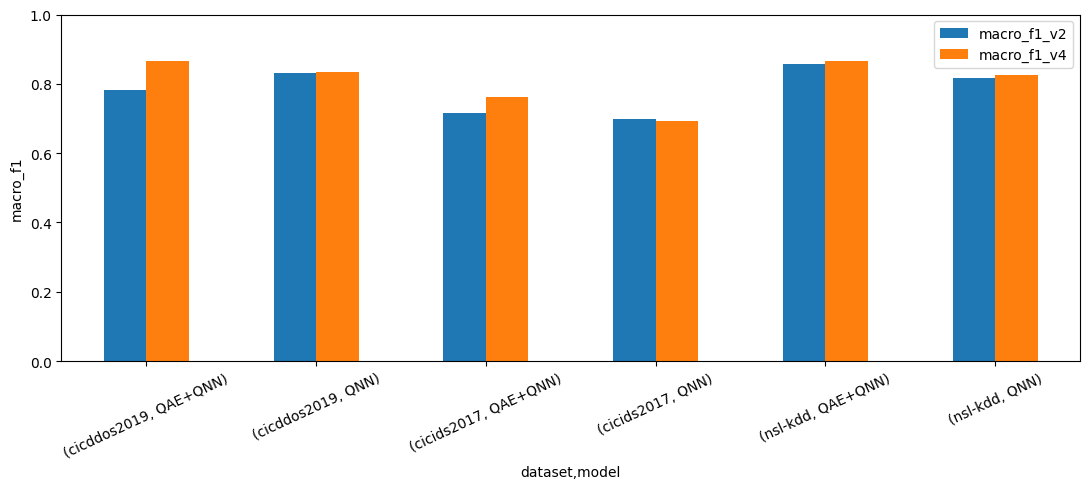

auc_v2          auc_v4         delta_auc        
                     mean     std    mean     std      mean     std
dataset     model                                                  
cicddos2019 QAE    0.5548  0.2608  0.8965  0.0250    0.3417  0.2357
cicids2017  QAE    0.4329  0.0399  0.7294  0.0370    0.2965  0.0029
nsl-kdd     QAE    0.2925  0.0066  0.8848  0.0102    0.5922  0.0036

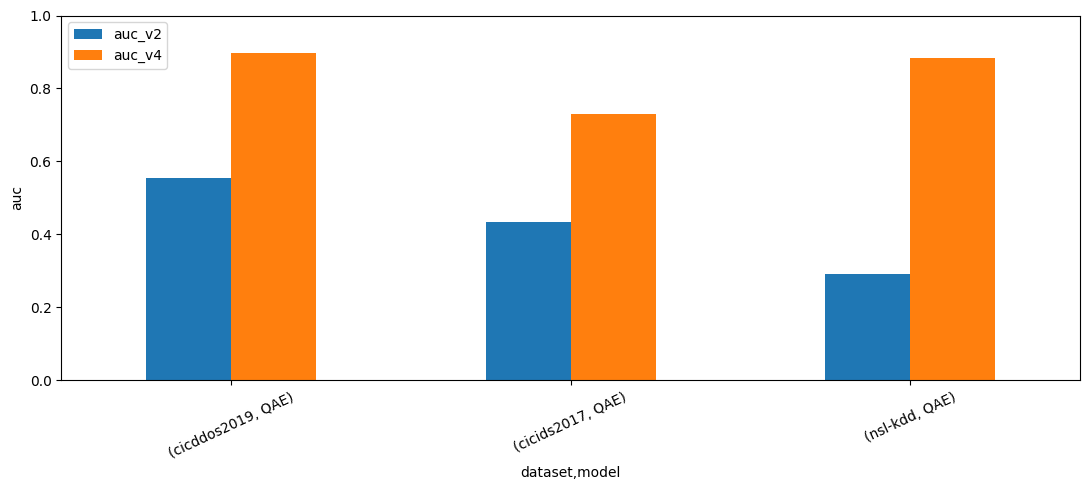

Saved: /content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae/output/train_v4/binary/v4_anchor_depth_v1


In [18]:
v4=pd.concat([pd.read_csv(p) for p in RUN.glob('*/metrics.csv')],ignore_index=True)
v2=pd.read_csv(BASELINE/'all_metrics.csv')
assert len(v4)==18, 'Chưa đủ 6 fold x 3 mô hình'
v4.to_csv(RUN/'all_metrics.csv',index=False)
keys=['dataset','seed','fold','data_hash','task','model']
a=v4.copy(); a['model']=a.model.str.replace(' V4','',regex=False)
paired=a.merge(v2,on=keys,suffixes=('_v4','_v2'),validate='one_to_one'); assert len(paired)==18
for metric in ['macro_f1','auc','accuracy','recall','fpr']:
    paired['delta_'+metric]=paired[metric+'_v4']-paired[metric+'_v2']
paired.to_csv(RUN/'paired_comparison.csv',index=False)
for task,metric in [('classification','macro_f1'),('anomaly','auc')]:
    z=paired[paired.task==task]; cols=[metric+'_v2',metric+'_v4','delta_'+metric]
    summary=z.groupby(['dataset','model'])[cols].agg(['mean','std']); display(summary.round(4)); summary.to_csv(RUN/f'{task}_comparison.csv')
    ax=z.groupby(['dataset','model'])[[metric+'_v2',metric+'_v4']].mean().plot.bar(figsize=(11,5),ylim=(0,1),rot=25)
    ax.set_ylabel(metric); plt.tight_layout(); plt.savefig(RUN/f'{task}_comparison.png',dpi=180); plt.show()
print('Saved:',RUN)


## C. Ablation Study
Cố định các yếu tố còn lại theo thiết kế đã chạy.

## Ablation Study — chạy sau khi V4 hoàn thành
Dùng pipeline đã lưu của V4. Không chọn cấu hình bằng test. Đây là phân tích khám phá trên outer test đã xem. Fusion cố định QAE V4 kể cả khi Hybrid gốc chọn QAE V2; early stopping so với checkpoint 100 epoch.

In [19]:
# Ablation: mỗi cặp dùng cùng split, seed, preprocessing và cấu hình còn lại.
AB=RUN/'ablation_v1'; AB.mkdir(exist_ok=True)
from sklearn.metrics import roc_auc_score

def fixed_training(A,y,B,yb,seed,depth,lr,w):
    torch.manual_seed(seed)
    m=ImprovedQNN(A.shape[1]-6,depth,w)
    opt=torch.optim.Adam(m.parameters(),lr=lr,weight_decay=1e-4)
    loss=nn.CrossEntropyLoss(weight=torch.tensor(len(y)/(2*np.bincount(y)),dtype=torch.float32))
    dl=DataLoader(TensorDataset(torch.tensor(A,dtype=torch.float32),torch.tensor(y,dtype=torch.long)),batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(seed))
    for ep in range(100):
        m.train()
        for x,t in dl:
            opt.zero_grad(); l=loss(m(x),t); l.backward(); opt.step()
    return m

for ds,d in cleaned.items():
    dh=hashlib.sha256(pd.util.hash_pandas_object(d,index=True).values.tobytes()).hexdigest()[:12]
    for fi,(X,y,enc,fit,val,cl,te) in enumerate(split_data(d,K,42),1):
        name=f'{ds}_{dh}_s42_f{fi}'; dest=RUN/name; target=AB/f'{name}.csv'
        if target.exists(): print('Skip',name); continue
        p=joblib.load(dest/'pipeline.joblib')
        for key,idx in [('fit',fit),('val',val),('te',te)]: assert np.array_equal(p[key],idx),key
        tr,va=p['tr'],p['va']; seed=42
        assert not set(tr)&set(va) and not set(te)&(set(tr)|set(va))
        Q=scale(X,p['qae_scaler'],p['qae_logmask']); C=scale(X,p['classifier_scaler'],p['classifier_logmask'])
        depth=p['qae_depth']; anchor=p['anchor']; rows=[]
        def record(group,variant,task,**kw):
            rows.append(dict(dataset=ds,fold=fi,seed=seed,group=group,variant=variant,task=task,**kw))
        # QAE: kiểm soát depth khi thay anchor, và ngược lại.
        for dep,a in sorted(set([(depth,0.),(depth,1.)]+[(i,anchor) for i in (1,2,3)])):
            theta,loss,ok=fit_v4(Q[fit],seed,dep,a)
            F=features_v4(Q,theta,dep,a); thr=np.quantile(F[val,0],.9)
            met=anomaly_metrics(y[te],F[te,0],thr)
            if dep==depth: record('anchor',str(a),'anomaly',depth=dep,anchor=a,**met)
            if a==anchor: record('qae_depth',str(dep),'anomaly',depth=dep,anchor=a,**met)
        # Fusion: cố định QAE cải tiến và cấu hình QNN đã chọn của Hybrid.
        cfg=joblib.load(dest/'QAE+QNN V4_config.joblib')
        F=features_v4(Q,p['qae_theta'],depth,anchor)
        Fz=StandardScaler().fit(F[tr]).transform(F)
        dep,lr=cfg['depth'],cfg['lr']
        variants=[('no_QAE',C,1.),('raw',np.column_stack([C,F]),1.),('normalized',np.column_stack([C,Fz]),1.),('normalized_weight025',np.column_stack([C,Fz]),.25)]
        for label,H,w in variants:
            m,f,ep=tune_one(H[tr],y[tr],H[va],y[va],seed,dep,lr,w)
            record('fusion',label,'classification',epoch=ep,**metrics(y[te],predict_v4(m,H[te])))
        # Early stopping/checkpoint so với đúng 100 epoch, cùng đầu vào.
        H=np.column_stack([C,Fz]); w=1.
        m,f,ep=tune_one(H[tr],y[tr],H[va],y[va],seed,dep,lr,w)
        record('early_stopping','validation_checkpoint','classification',epoch=ep,**metrics(y[te],predict_v4(m,H[te])))
        m=fixed_training(H[tr],y[tr],H[va],y[va],seed,dep,lr,w)
        record('early_stopping','fixed_100','classification',epoch=100,**metrics(y[te],predict_v4(m,H[te])))
        tmp=target.with_suffix('.tmp'); pd.DataFrame(rows).to_csv(tmp,index=False); tmp.replace(target)
        print('Done',name,flush=True)


Skip cicddos2019_9f218da7e1ac_s42_f1
Skip cicddos2019_9f218da7e1ac_s42_f2
Skip cicids2017_f9ca68a4db7d_s42_f1
Skip cicids2017_f9ca68a4db7d_s42_f2
Skip nsl-kdd_5395fa362f21_s42_f1
Skip nsl-kdd_5395fa362f21_s42_f2


In [ ]:
ab=pd.concat([pd.read_csv(p) for p in AB.glob('*_s42_f*.csv')],ignore_index=True)
assert ab.groupby(['dataset','fold']).ngroups==6
ab.to_csv(AB/'all_ablation.csv',index=False)
for group in ['anchor','qae_depth','fusion','early_stopping']:
    z=ab[ab.group==group]; metric='auc' if group in ['anchor','qae_depth'] else 'macro_f1'
    s=z.groupby(['dataset','variant'])[metric].agg(['mean','std','count']); display(s.round(4)); s.to_csv(AB/f'{group}_summary.csv')
    ax=s['mean'].unstack().plot.bar(figsize=(10,4),ylim=(0,1),rot=0); ax.set_ylabel(metric); ax.set_title(group); plt.tight_layout(); plt.savefig(AB/f'{group}.png',dpi=180); plt.show()
print('Saved:',AB)


## D. Bảng tổng hợp chính thức
Giữ kết quả đối chứng V2, thay QAE/QNN/Hybrid bằng V4 theo thiết kế cải tiến đã định. QAE+MLP vẫn là V2. Cùng outer test nhưng ngân sách tuning và tập classifier train không hoàn toàn giống nhau.

mean     std  count
dataset     model       version                       
cicddos2019 ClassicalAE V2       0.8534  0.0276      2
            QAE         V4       0.8965  0.0250      2
cicids2017  ClassicalAE V2       0.7329  0.0363      2
            QAE         V4       0.7294  0.0370      2
nsl-kdd     ClassicalAE V2       0.8354  0.0136      2
            QAE         V4       0.8848  0.0102      2

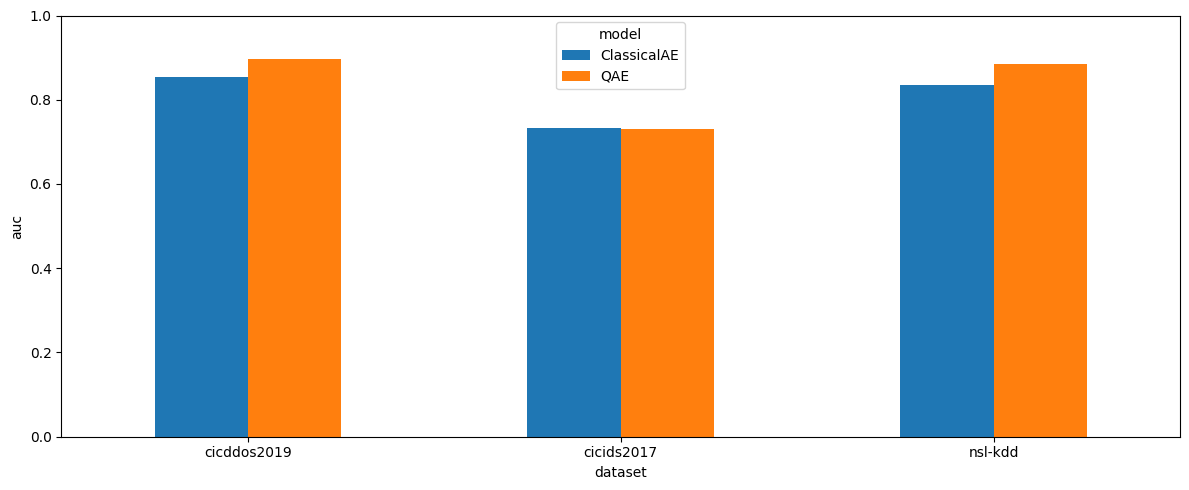

mean     std  count
dataset     model   version                       
cicddos2019 CNN     V2       0.8321  0.0086      2
            MLP     V2       0.8373  0.1112      2
            QAE+MLP V2       0.8651  0.0526      2
            QAE+QNN V4       0.8652  0.0356      2
            QNN     V4       0.8327  0.0359      2
            RF      V2       0.9379  0.0216      2
            XGBoost V2       0.9604  0.0093      2
cicids2017  CNN     V2       0.8084  0.0393      2
            MLP     V2       0.8062  0.0448      2
            QAE+MLP V2       0.8066  0.0146      2
            QAE+QNN V4       0.7630  0.0063      2
            QNN     V4       0.6934  0.0647      2
            RF      V2       0.8679  0.0080      2
            XGBoost V2       0.8678  0.0113      2
nsl-kdd     CNN     V2       0.8541  0.0147      2
            MLP     V2       0.8476  0.0236      2
            QAE+MLP V2       0.8697  0.0317      2
            QAE+QNN V4       0.8662  0.0209      2
            QNN     V4       0.8250  0.0343      2
            RF      V2       0.9172  0.0045      2
            XGBoost V2       0.9140  0.0060      2

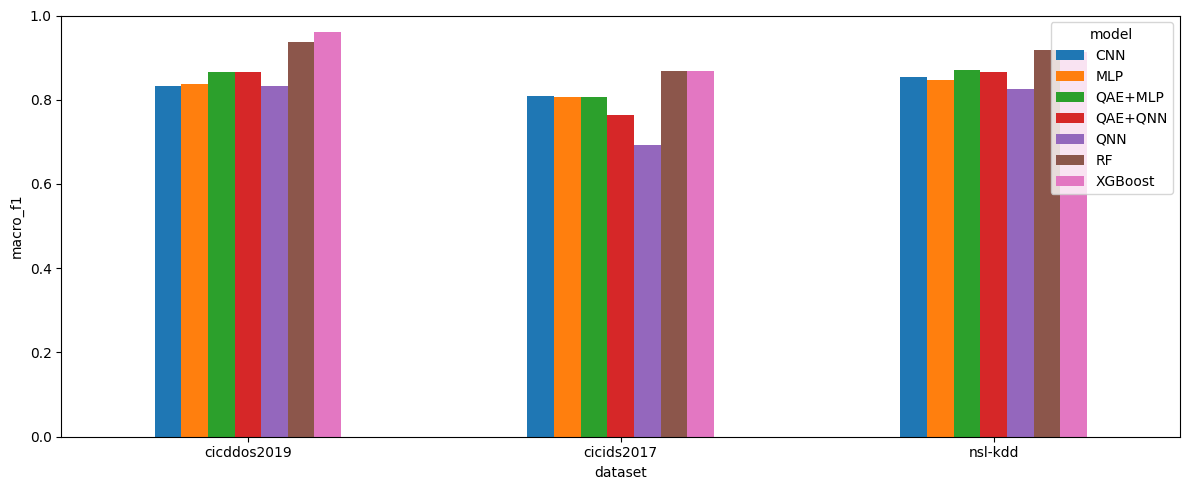

Saved: /content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae/output/train_benchmark_final


In [20]:
final_dir=BASE/'output/train_benchmark_final'
final_dir.mkdir(parents=True,exist_ok=True)
old=pd.read_csv(BASELINE/'all_metrics.csv')
new=pd.read_csv(RUN/'all_metrics.csv')
keys=['dataset','seed','fold','data_hash','task','model']
assert len(old)==54 and len(new)==18
old=old.assign(version='V2')
new=new.assign(version='V4')
new['model']=new.model.str.replace(' V4','',regex=False)
assert len(new.merge(old,on=keys,validate='one_to_one'))==18
final=pd.concat([old[~old.model.isin(['QAE','QNN','QAE+QNN'])],new],ignore_index=True)
assert len(final)==54 and not final.duplicated(keys).any()
final.to_csv(final_dir/'all_metrics.csv',index=False)
for task,metric in [('anomaly','auc'),('classification','macro_f1')]:
    z=final[final.task==task]
    s=z.groupby(['dataset','model','version'])[metric].agg(['mean','std','count'])
    display(s.round(4)); s.to_csv(final_dir/f'{task}_summary.csv')
    ax=z.groupby(['dataset','model'])[metric].mean().unstack().plot.bar(figsize=(12,5),rot=0,ylim=(0,1))
    ax.set_ylabel(metric); plt.tight_layout(); plt.savefig(final_dir/f'{task}.png',dpi=180); plt.show()
import shutil
for src in [RUN/'paired_comparison.csv',RUN/'classification_comparison.csv',RUN/'anomaly_comparison.csv',AB/'all_ablation.csv']+list(AB.glob('*_summary.csv')):
    if src.exists(): shutil.copy2(src,final_dir/src.name)
print('Saved:',final_dir)

In [21]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

BASE = Path(
    '/content/drive/MyDrive/lab_MHMM/DoAn/ddos_qae'
)

sources = {
    'final': BASE / 'output/train_benchmark_final',

    'baseline': BASE / (
        'output/train_v2_lite/binary/b413000dc828'
    ),

    'improved': BASE / (
        'output/train_v4/binary/v4_anchor_depth_v1'
    )
}

ZIP_PATH = Path('/content/Benchmark_Results.zip')

extensions = {
    '.csv', '.png', '.json', '.svg', '.pdf'
}

with ZipFile(ZIP_PATH, 'w', ZIP_DEFLATED) as z:

    for name, folder in sources.items():

        assert folder.exists(), f'Thiếu thư mục: {folder}'

        for path in folder.rglob('*'):

            if path.is_file() and path.suffix in extensions:

                z.write(
                    path,
                    f'{name}/{path.relative_to(folder)}'
                )

print('Đã đóng gói:', ZIP_PATH)

print(
    'Dung lượng:',
    round(ZIP_PATH.stat().st_size / 1024**2, 2),
    'MB'
)

files.download(str(ZIP_PATH))

Đã đóng gói: /content/Benchmark_Results.zip
Dung lượng: 0.38 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>